In [40]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, mean_absolute_error, mean_squared_error, r2_score
)




In [41]:
df = pd.read_csv('ecommerce_clean_data.csv')

In [42]:
df

,Order_ID,OrderDate,customer_Id,Paymentmethod,orderStatus,customer_name,Gender,Age,City,Region,...,Costprice,Sellingprice,Year,Month,MonthName,Quarter,Day,OrderDayName,YearMonth,Profit_Margin
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,5353.0,10018.0,2026,1,January,1,19,Monday,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,3112.0,5568.0,2026,1,January,1,19,Monday,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,5905.0,10331.0,2026,2,February,1,14,Saturday,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3425.0,4363.0,2026,2,February,1,14,Saturday,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,3999.0,6601.0,2025,11,November,4,21,Friday,2025-11,36.229758
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12553,O04999,2026-03-20,C0371,Credit Card,Delivered,Customer_0371,Female,46,Lucknow,North,...,6411.0,9277.0,2026,3,March,1,20,Friday,2026-03,27.256429
12554,O04999,2026-03-20,C0371,Credit Card,Delivered,Customer_0371,Female,46,Lucknow,North,...,2528.0,3517.0,2026,3,March,1,20,Friday,2026-03,15.435950
12555,O05000,2025-12-16,C0777,COD,Delivered,Customer_0777,Male,56,Chennai,South,...,3254.0,4834.0,2025,12,December,4,16,Tuesday,2025-12,20.806055
12556,O05000,2025-12-16,C0777,COD,Delivered,Customer_0777,Male,56,Chennai,South,...,433.0,791.0,2025,12,December,4,16,Tuesday,2025-12,31.573957


In [43]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

In [44]:
df

,Order_ID,OrderDate,customer_Id,Paymentmethod,orderStatus,customer_name,Gender,Age,City,Region,...,Costprice,Sellingprice,Year,Month,MonthName,Quarter,Day,OrderDayName,YearMonth,Profit_Margin
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,5353.0,10018.0,2026,1,January,1,19,Monday,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,3112.0,5568.0,2026,1,January,1,19,Monday,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,5905.0,10331.0,2026,2,February,1,14,Saturday,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3425.0,4363.0,2026,2,February,1,14,Saturday,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,3999.0,6601.0,2025,11,November,4,21,Friday,2025-11,36.229758
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12553,O04999,2026-03-20,C0371,Credit Card,Delivered,Customer_0371,Female,46,Lucknow,North,...,6411.0,9277.0,2026,3,March,1,20,Friday,2026-03,27.256429
12554,O04999,2026-03-20,C0371,Credit Card,Delivered,Customer_0371,Female,46,Lucknow,North,...,2528.0,3517.0,2026,3,March,1,20,Friday,2026-03,15.435950
12555,O05000,2025-12-16,C0777,COD,Delivered,Customer_0777,Male,56,Chennai,South,...,3254.0,4834.0,2025,12,December,4,16,Tuesday,2025-12,20.806055
12556,O05000,2025-12-16,C0777,COD,Delivered,Customer_0777,Male,56,Chennai,South,...,433.0,791.0,2025,12,December,4,16,Tuesday,2025-12,31.573957


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12558 entries, 0 to 12557
Data columns (total 30 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Order_ID         12558 non-null  object        
 1   OrderDate        12558 non-null  datetime64[ns]
 2   customer_Id      12558 non-null  object        
 3   Paymentmethod    12558 non-null  object        
 4   orderStatus      12558 non-null  object        
 5   customer_name    12558 non-null  object        
 6   Gender           12558 non-null  object        
 7   Age              12558 non-null  int64         
 8   City             12558 non-null  object        
 9   Region           12558 non-null  object        
 10  SignupDate       12558 non-null  object        
 11  OrderDetails_ID  12558 non-null  object        
 12  product_ID       12558 non-null  object        
 13  Quantity         12558 non-null  int64         
 14  Unitprice        12558 non-null  float

In [46]:
#target variable define 
target = 'Profit'


In [47]:
#data leakage samjo 


In [48]:
#feature selection 
features = [
    'Quantity',
    'Unitprice',
    'Discountprice',
    'Category',
    'Region',
    'Paymentmethod'
]


In [49]:
 # step x and y
x = df[features]
y = df[target]

In [50]:
# step checking missing value 
x.isnull().sum()

Quantity         0
Unitprice        0
Discountprice    0
Category         0
Region           0
Paymentmethod    0
dtype: int64

In [51]:
y.isnull().sum()

np.int64(0)

In [52]:
x.dtypes

Quantity           int64
Unitprice        float64
Discountprice    float64
Category          object
Region            object
Paymentmethod     object
dtype: object

In [53]:
y.dtypes

dtype('float64')

In [54]:
# data training and test split 
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [55]:
# catogorical column 
categorical_feature = [ 
    'Category',
    'Region',
    'Paymentmethod'
]

In [56]:
numeical_features = [
    'Quantity',
    'Unitprice',
    'Discountprice'
]

In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [58]:
# step 11 one hot encoding 
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_feature)
    ],
    remainder='passthrough'
)

In [59]:

preprocessor 

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{fea

In [61]:
from sklearn.ensemble import RandomForestRegressor

In [62]:
# model create 
model = RandomForestRegressor(
    n_estimators=200,      
    random_state=42, 
    n_jobs=-1  
)

In [63]:
#13 pipelines
pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', model)
])

In [64]:
# Train the model
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains

In [65]:
# Make predictions
y_pred = pipeline.predict(X_test)

In [66]:
# Create a DataFrame to compare actual and predicted values
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison.head(10)

,Actual,Predicted
0,3068.40,3056.53200
1,8642.00,9045.08300
2,502.35,496.76650
3,2876.35,2876.35000
4,1755.80,1751.57300
5,630.00,623.52150
6,-233.25,-172.29725
7,2379.80,2397.82000
8,2291.30,2303.24650
9,2184.00,2197.00000


In [67]:
# Calculate MAE
mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 73.4593164808931


In [68]:
# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)

RMSE: 213.34551453319514


In [69]:
# Calculate R2 score
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)


R2 Score: 0.9979492010789576


In [70]:
#complete evaluation# Print results
print("MAE  :", mae)
print("RMSE :", rmse)
print("R2   :", r2)


MAE  : 73.4593164808931
RMSE : 213.34551453319514
R2   : 0.9979492010789576


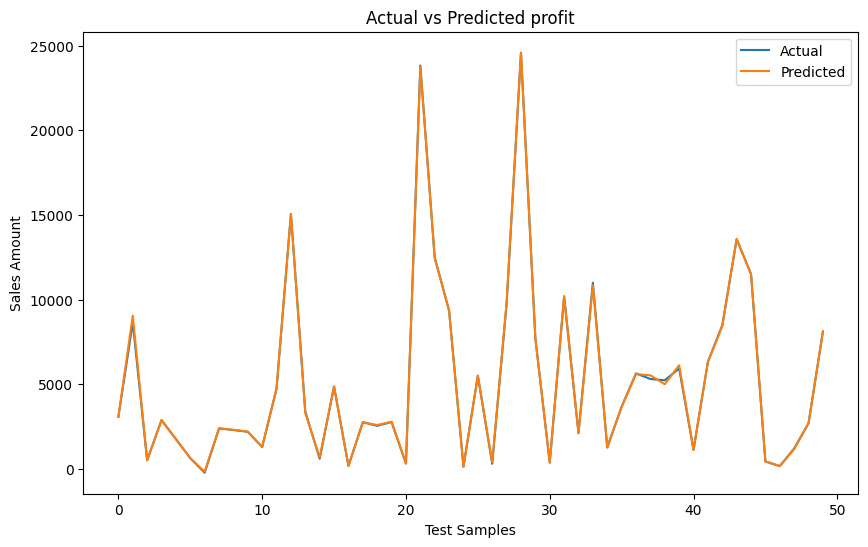

In [75]:
import matplotlib.pyplot as plt

# Plot actual and predicted values
plt.figure(figsize=(10, 6))

plt.plot(
    y_test.values[:50],
    label='Actual'
)

plt.plot(
    y_pred[:50],
    label='Predicted'
)

plt.title('Actual vs Predicted profit')
plt.xlabel('Test Samples')
plt.ylabel('Sales Amount')

plt.legend()
plt.show()

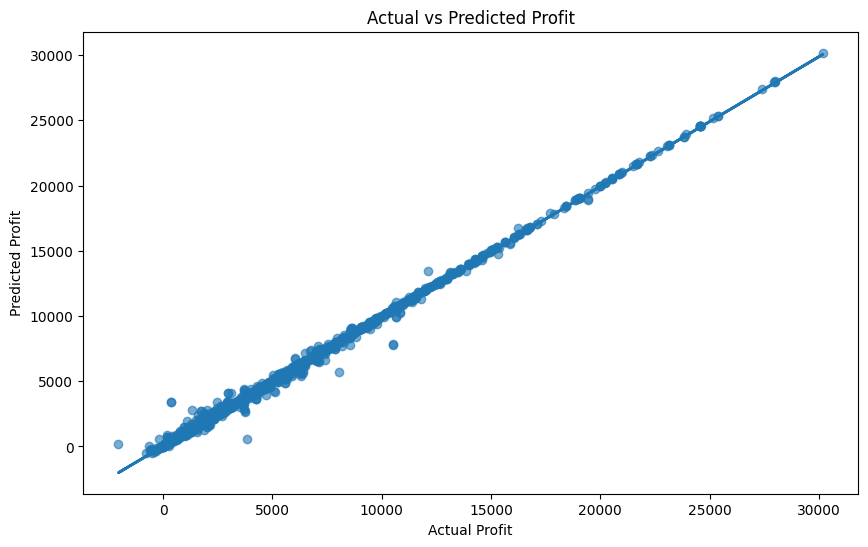

In [73]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))

# Actual vs Predicted dots
plt.scatter(y_test, y_pred, alpha=0.6)

# Trend line
z = np.polyfit(y_test, y_pred, 1)
p = np.poly1d(z)

plt.plot(y_test, p(y_test), linewidth=2)

plt.title("Actual vs Predicted Profit")
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")

plt.show()

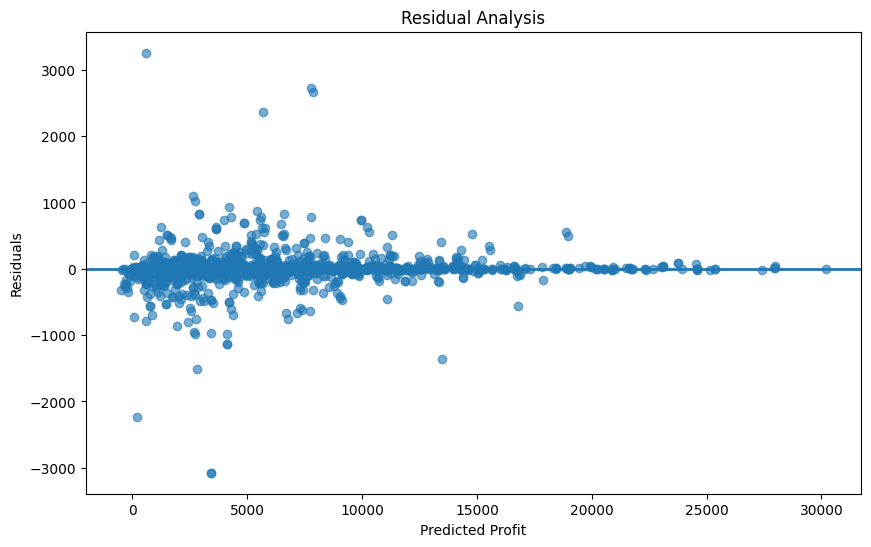

In [77]:
import matplotlib.pyplot as plt

# Calculate residuals
residuals = y_test - y_pred

# Plot residuals
plt.figure(figsize=(10, 6))

plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline(y=0, linewidth=2)

plt.title("Residual Analysis")
plt.xlabel("Predicted Profit")
plt.ylabel("Residuals")

plt.show()